c:\src\ASEN5053\project\python\.conda\lib\site-packages\poliastro\core\maneuver.py:49: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 1, 'A', False, aligned=True))
  r_i = norm(r_i)


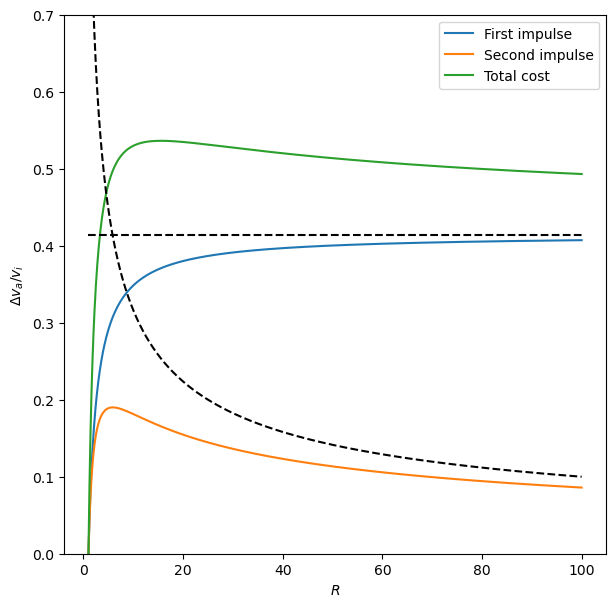

In [1]:

import numpy as np
import matplotlib.pyplot as plt
#import pandas as pd
from poliastro.maneuver import Maneuver
import astropy
from astropy import units as u
import poliastro
from poliastro.bodies import Earth, Sun, Jupiter
from poliastro.twobody import Orbit
from astropy import units as u
from poliastro.util import norm

# Data from Curtis, example 4.3
r = [-6045, -3490, 2500] << u.km
v = [-3.457, 6.618, 2.533] << u.km / u.s

orb = Orbit.from_vectors(Earth, r, v)
#orb.plot()



dv = [5, 0, 0] << (u.m / u.s)

imp = Maneuver.impulse(dv)
imp = Maneuver((0 << u.s, dv))  # Equivalent


ss_i = Orbit.circular(Earth, alt=200 * u.km)
ss_i
r_i = ss_i.a.to(u.km)
r_i

#orb_i
v_i_vec = ss_i.v.to(u.km / u.s)
v_i = norm(v_i_vec)
v_i

ss_f = Orbit.circular(Jupiter,alt=1000000 << u.km)
ss_f
r_f = ss_f.a.to(u.km)
r_f

v_f_vec = ss_f.v.to(u.km / u.s)
v_f = norm(v_f_vec)
v_f



#7078 x 7078 km x 0.0 deg (GCRS) orbit around Earth#
# hoh = Maneuver.hohmann(orb_i, orb_f << u.km)
#hoh.get_total_cost()
#<Quantity 3.6173981270031357 km / s>
#transit = hoh.get_total_time()
#<Quantity 15729.741535747102 s>

#sec2day = 60*60/24
#transitDays = transit/sec2day
#transitDays


N = 1000
dv_a_vector = np.zeros(N) * u.km / u.s
dv_b_vector = dv_a_vector.copy()
r_f_vector = r_i * np.linspace(1, 100, num=N)
for ii, r_f in enumerate(r_f_vector):
    man = Maneuver.hohmann(ss_i, r_f)
    (_, dv_a), (_, dv_b) = man.impulses
    dv_a_vector[ii] = norm(dv_a)
    dv_b_vector[ii] = norm(dv_b)
    
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    (r_f_vector / r_i).value, (dv_a_vector / v_i).value, label="First impulse"
)
ax.plot(
    (r_f_vector / r_i).value, (dv_b_vector / v_i).value, label="Second impulse"
)
ax.plot(
    (r_f_vector / r_i).value,
    ((dv_a_vector + dv_b_vector) / v_i).value,
    label="Total cost",
)

ax.plot((r_f_vector / r_i).value, np.full(N, np.sqrt(2) - 1), "k--")
ax.plot((r_f_vector / r_i).value, (1 / np.sqrt(r_f_vector / r_i)).value, "k--")

ax.set_ylim(0, 0.7)
ax.set_xlabel("$R$")
ax.set_ylabel("$\Delta v_a / v_i$")

plt.legend()
fig.savefig("hohmann.png")